In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression as LR
from sklearn.metrics import accuracy_score as sk_score

,0,1
0,1.863411,0.087646
1,-1.530997,1.901182
2,-0.017224,-2.591112
3,-2.032039,-1.801162
4,4.620555,0.901124


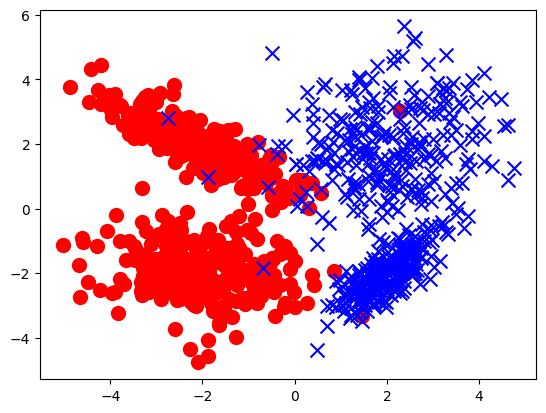

In [ ]:
X,y = make_classification (n_samples=1000,
                          n_features=2,
                          n_informative=2,
                          n_redundant=0,
                          n_classes=2,
                          class_sep=2,
                          random_state=1)
display(pd.DataFrame(X).head())
plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
plt.show()

#1 Выведите результаты работы библиотечной модели - в численном и в графическом виде.

In [ ]:
def VISUALISE_2d(X,y,predictor):
  xx, yy = np.meshgrid(
    np.arange(X.min(axis=0)[0]-1, X.max(axis=0)[0]+1, 0.01),
    np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01))
  XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
  print(XX.ndim)
  #XX = np.array([(1, *xx) for xx in XX])
  y_pred = predictor.predict(XX)
  y_pred = y_pred.reshape(xx.shape)
  plt.contourf(xx, yy, y_pred, alpha=0.4)
  plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
  plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)

In [ ]:
model = LR()
model.fit(X, y)
y_pred_lr = model.predict(X)

2


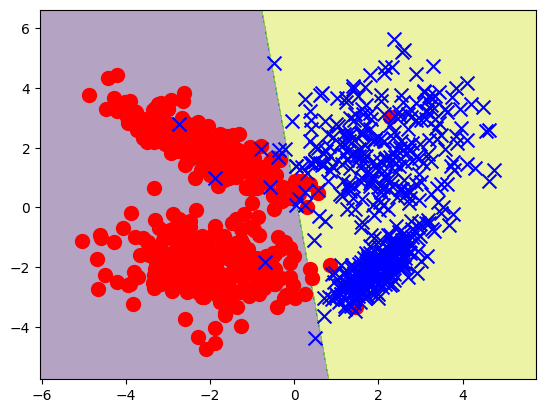

In [ ]:
VISUALISE_2d(X,y,model)

#2 Проверьте работу модели с другими значениями скорости обучения. Найдите значение, при котором градиентный спуск расходится.

## Функции обеспечивающие классификацию

### Градиентный спуск

In [ ]:
class SGD():
    def __init__(self, alpha=0.5, n_iters=1000):
        self.b = None
        self._alpha = alpha
        self._n_iters = n_iters
    def gradient_step(self, b, b_grad):
        return b - self._alpha * b_grad
    def optimize(self, X, y, start_b, n_iters):
        b = start_b.copy()
        for i in range(n_iters):
            b_grad = self.grad_func(X, y, b)
            b = self.gradient_step(b, b_grad)
        return b
    def fit(self, X, y):
        m = X.shape[1]
        start_b = np.ones(m)
        self.b = self.optimize(X, y, start_b, self._n_iters)

### Логистическая регрессия

In [ ]:
class LogReg(SGD):
    def sigmoid(self, X, b):
        #print(1. / (1. + np.exp(-X.dot(b))))
        return 1. / (1. + np.exp(-X.dot(b)))
    def grad_func(self, X, y, b):
        n = X.shape[0]
        grad = 1. / n * X.transpose().dot(self.sigmoid(X, b) - y)
        return grad
    def predict_proba(self, X):
        return self.sigmoid(X, self.b)
    def predict(self, X):
        y_pred = self.predict_proba(X) > 0.5
        return y_pred
    def plot_data(self, X):
        plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
        plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
        plt.show()
    def plot_classified_data(self, X):
        xx, yy = np.meshgrid(
        np.arange(X.min(axis=0)[0]-1, X.max(axis=0)[0]+1, 0.01),
        np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01))
        XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
        Z = self.predict_proba(XX)
        Z = Z.reshape(xx.shape)
        plt.contourf(xx, yy, Z, alpha=0.4)
        plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
        plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
        plt.show()

## Проверьте работу модели с другими значениями скорости обучения. Найдите значение, при котором градиентный спуск расходится.

In [ ]:

X,y = make_classification (n_samples=1000,n_features=2,n_informative=2,n_redundant=0,n_classes=2,class_sep=2,random_state=1)
X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])

n=100
#fig,ax = plt.subplots(n,1)

for i in range(n):
  logreg = LogReg(alpha=i*1.0)
  logreg.fit(X, y)
  y_pred = logreg.predict(X)
  #logreg.plot_classified_data(X)
  print(f'{i}\n{sk_score(y, y_pred)}\n\n')

0
0.706


1
0.976


2
0.976


3
0.976


4
0.976


5
0.976


6
0.976


7
0.976


8
0.976


9
0.976


10
0.976


11
0.976


12
0.976


13
0.976


14
0.976


15
0.976


16
0.976


17
0.976


18
0.976


19
0.976


20
0.976


21
0.976


22
0.976


23
0.978


24
0.975


25
0.976


26
0.975


27
0.977


28
0.977


29
0.979


30
0.976


31
0.978


32
0.976


33
0.978


34
0.98


35
0.98


36
0.977


37
0.976


38
0.976


39
0.976


40
0.977


41
0.98


42
0.978


43
0.976


44
0.975


45
0.976


46
0.976


47
0.977


48
0.977


49
0.976


50
0.976


51
0.977


52
0.978


53
0.976


54
0.977


55
0.977


56
0.978


57
0.976


58
0.976


59
0.976


60
0.978


61
0.976


62
0.976


63
0.978


64
0.977


65
0.977


66
0.976


67
0.977


68
0.977


69
0.976


70
0.977


71
0.977


72
0.976


73
0.977


74
0.977


75
0.977


76
0.976


77
0.979


78
0.978


79
0.976


80
0.976


81
0.975


82
0.978


83
0.976


84
0.977


85
0.977


86
0.976


87
0.976


88
0.978


89
0.977


90
0.977


91
0.977




<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))
<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))
<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))


92
0.795


93
0.974


94
0.978




<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))
<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))


95
0.976


96
0.976




<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))
<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))


97
0.976


98
0.977


99
0.976




<ipython-input-7-00a59f7200f3>:4: RuntimeWarning: overflow encountered in exp
  return 1. / (1. + np.exp(-X.dot(b)))


#3 Модифицируйте код модели таким образом, чтобы фиктивный столбец единиц добавлялся к матрице признаков внутри класса

## Функции обеспечивающие классификацию

### Градиентный спуск

In [ ]:
class SGD():
    def __init__(self, alpha=0.5, n_iters=1000):
        self.b = None
        self._alpha = alpha
        self._n_iters = n_iters
    def gradient_step(self, b, b_grad):
        return b - self._alpha * b_grad
    def optimize(self, X, y, start_b, n_iters):
        b = start_b.copy()
        for i in range(n_iters):
            b_grad = self.grad_func(X, y, b)
            b = self.gradient_step(b, b_grad)
        return b
    def fit(self, X, y):
        X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
        m = X.shape[1]
        start_b = np.ones(m)
        self.b = self.optimize(X, y, start_b, self._n_iters)

### Логистическая регрессия

In [ ]:
class LogReg(SGD):
    def sigmoid(self, X, b):
        #print(1. / (1. + np.exp(-X.dot(b))))
        return 1. / (1. + np.exp(-X.dot(b)))
    def grad_func(self, X, y, b):
        n = X.shape[0]
        grad = 1. / n * X.transpose().dot(self.sigmoid(X, b) - y)
        return grad
    def predict_proba(self, X):
        #X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
        return self.sigmoid(X, self.b)
    def predict(self, X):
        X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
        y_pred = self.predict_proba(X) > 0.5
        return y_pred
    def plot_data(self, X):
        plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
        plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
        plt.show()
    def plot_classified_data(self, X):
        xx, yy = np.meshgrid(
        np.arange(X.min(axis=0)[0]-1, X.max(axis=0)[0]+1, 0.01),
        np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01))
        XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
        Z = self.predict_proba(XX)
        Z = Z.reshape(xx.shape)
        plt.contourf(xx, yy, Z, alpha=0.4)
        plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
        plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
        plt.show()

## тест

In [ ]:
X,y = make_classification (n_samples=1000,n_features=2,n_informative=2,n_redundant=0,n_classes=2,class_sep=2,random_state=1)

logreg = LogReg(alpha=1.0)
logreg.fit(X, y)
y_pred = logreg.predict(X)
sk_score(y,y_pred)

0.976

#4 Поэкспериментируйте с разными значениями параметра class_sep при генерации датасета. Визуализируйте полученные распределения. Сделайте вывод о том, как этот параметр влияет на точность получаемых моделей.

,0,1
0,9.863411,8.087646
1,-9.530997,9.901182
2,-8.017224,-10.591112
3,-10.032039,-9.801162
4,12.620555,8.901124


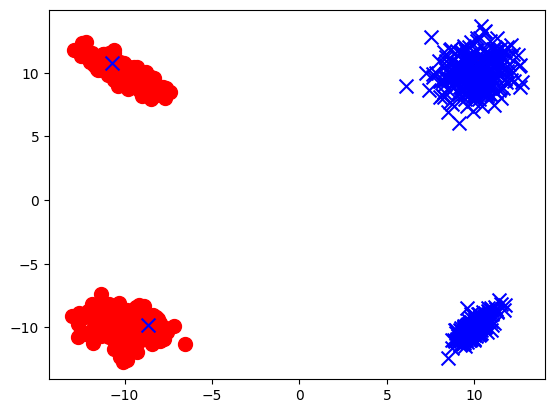

In [ ]:
X,y = make_classification (n_samples=1000,
                          n_features=2,
                          n_informative=2,
                          n_redundant=0,
                          n_classes=2,
                          class_sep=10,
                          random_state=1)
display(pd.DataFrame(X).head())
plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
plt.show()

In [ ]:
def VISUALISE_2d(X,y,predictor):
  xx, yy = np.meshgrid(
    np.arange(X.min(axis=0)[0]-1, X.max(axis=0)[0]+1, 0.01),
    np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01))
  XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
  print(XX.ndim)
  #XX = np.array([(1, *xx) for xx in XX])
  y_pred = predictor.predict(XX)
  y_pred = y_pred.reshape(xx.shape)
  plt.contourf(xx, yy, y_pred, alpha=0.4)
  plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
  plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
  plt.show()

## Проитерируемся по возможным значением class_sep:

In [ ]:
for i in np.linspace(0.1,10,50):
    X,y = make_classification (n_samples=1000,
                              n_features=2,
                              n_informative=2,
                              n_redundant=0,
                              n_classes=2,
                              class_sep=i,
                              random_state=1)
    model = LR()
    model.fit(X, y)
    print(f'\n\nclass_sep == {i}\nscore is: {sk_score(y,model.predict(X))}')
    VISUALISE_2d(X,y,model)


Output hidden; open in https://colab.research.google.com to view.

## вывод:
Чем больше class_sep, тем более явно разделенны между собой классы, соответственно выше точность модели логистической регрессии

# 5 Сгенерируйте датасет с большим числом признаков и примените к нему созданную модель.

In [ ]:
k = 500
l = 0.2
X,y = make_classification (n_samples=1000,
                              n_features=k,
                              n_informative=2,
                              n_redundant=0,
                              n_classes=2,
                              class_sep=l,
                              random_state=1)
model = LR()
model.fit(X, y)
display(X.shape)
display(pd.DataFrame(X).head())
print(f'class_sep == {l}\nnumber of features == {k}\nscore is: {sk_score(y,model.predict(X))}')


(1000, 500)

,0,1,2,3,4,5,6,7,8,9,...,490,491,492,493,494,495,496,497,498,499
0,-0.102555,0.048338,-1.544887,-3.003949,1.355498,1.768577,0.823068,0.539175,-0.102802,-0.041664,...,0.842544,0.656517,0.061590,-0.705001,0.242771,1.292674,-0.133713,-0.724575,1.433841,-2.311276
1,-0.889826,-0.234389,-0.406626,0.236845,0.419754,-1.429631,0.189967,0.164368,-1.192062,0.642450,...,2.167444,-0.521039,-0.848381,-0.370327,-0.111051,-0.351814,0.970376,-0.548283,-0.798184,0.121862
2,1.144624,-0.477080,-1.319805,0.080293,-0.114427,-0.482903,-0.766248,-0.591117,-0.993993,-0.818350,...,1.045814,1.025044,-1.024142,1.715101,0.616938,-0.490617,-0.128193,-0.833885,-1.255935,1.071016
3,-0.519025,-0.453985,-0.514867,1.159290,-1.252404,1.056121,-0.246019,-1.327318,-0.289777,1.435908,...,0.113986,-0.490378,-1.383675,1.041318,1.044880,0.130961,-0.559716,-0.248543,-0.587074,-0.054463
4,-1.012017,-0.727750,1.916009,1.007921,-0.552746,-1.094911,0.090889,-0.509794,-0.895223,1.353685,...,-0.965025,-0.262504,-0.350757,-0.607516,0.676207,1.095193,0.656092,-1.979761,1.042065,1.622022


class_sep == 0.2
number of features == 500
score is: 0.913


# 6 Сгенерируйте датасет с большим количеством классов и реализуйте в классе алгоритм "один против всех". Решите задачу множественной классификации средствами sklearn.

## Функции обеспечивающие классификацию

### Градиентный спуск

In [ ]:
class SGD():
    def __init__(self, alpha=0.5, n_iters=1000):
        self.b = None
        self._alpha = alpha
        self._n_iters = n_iters
    def gradient_step(self, b, b_grad):
        return b - self._alpha * b_grad
    def optimize(self, X, y, start_b, n_iters):
        b = start_b.copy()
        for i in range(n_iters):
            b_grad = self.grad_func(X, y, b)
            b = self.gradient_step(b, b_grad)
        return b




    def fit(self, X, y):
        #X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
        m = X.shape[1]
        start_b = np.ones(m)
        #p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = [f'X{i}' for i in range(X.shape[1])]+['Y'])
        #print(p.head())
        #p1 = p.copy()
        #for i in p['Y'].unique():
          #p1.loc[p['Y']!=i,'Y']
          #p1 = p
        self.b = self.optimize(X, y, start_b, self._n_iters)

### Логистическая регрессия

In [ ]:
class LogReg(SGD):
    def sigmoid(self, X, b):
        return 1. / (1. + np.exp(-X.dot(b)))
    def grad_func(self, X, y, b):
        n = X.shape[0]
        grad = 1. / n * X.transpose().dot(self.sigmoid(X, b) - y)
        return grad
    def predict_proba(self, X):
        return self.sigmoid(X, self.b)
    def predict(self, X):
        #X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
        y_pred = self.predict_proba(X) > 0.5
        return y_pred
    def plot_data(self, X):
        plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
        plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
        plt.show()
    def plot_classified_data(self, X):
        xx, yy = np.meshgrid(
        np.arange(X.min(axis=0)[0]-1, X.max(axis=0)[0]+1, 0.01),
        np.arange(X.min(axis=0)[1]-1, X.max(axis=0)[1]+1, 0.01))
        XX = np.array(list(zip(xx.ravel(), yy.ravel()))).reshape((-1, 2))
        Z = self.predict_proba(XX)
        Z = Z.reshape(xx.shape)
        plt.contourf(xx, yy, Z, alpha=0.4)
        plt.scatter(X[:, 0][y==0], X[:, 1][y==0], marker="o", c='r', s=100)
        plt.scatter(X[:, 0][y==1], X[:, 1][y==1], marker="x", c='b', s=100)
        plt.show()

### мультрегрессия

In [ ]:
class LogRegMult(LogReg):
  def __init__(self):
    self.models=None
  def fit(self, X, y):
    X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
    p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = [f'X{i}' for i in range(X.shape[1])]+['Y'])
    self.models=[]
    for i in sorted(p['Y'].unique()):
      p1 = p.copy()
      p1.loc[p1['Y']!=i,'Y']=-1
      p1.loc[p1['Y']==i,'Y']=1
      p1.loc[p1['Y']==-1,'Y']=0
      #print(i,p1['Y'].sum())
      lr = LogReg()
      y_ = p1['Y'].values
      x_ = p1.drop(['Y'],axis=1).values
      #print(x_)
      #print(y_)
      #print(f'iter on class {i}')
      lr.fit(x_,y_)
      self.models.append(lr)
      #prediction = lr.predict(x_)
      #print(prediction)
      #p = p[np.invert(prediction)]
      #print(p.shape)
      #p.drop()
      '''
  def predict(self,X,y):
    X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
    p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = [f'X{i}' for i in range(X.shape[1])]+['Y'])
    #scores
    scores = []
    x_ = p.drop(['Y'],axis=1).values
    for i,j in zip(self.models,p['Y'].unique()):
      p1 = p.copy()
      p1.loc[p1['Y']!=i,'Y']=0
      p1.loc[p1['Y']==i,'Y']=1
      y_ = p1['Y'].values
      scores.append(sk_score(i.predict(x_),y_))
      '''
  def predict(self,X):
    X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
    predicts = []
    for i in self.models:
      predicts.append(i.predict(X))
    return predicts

  def predict_proba(self,X):
    X = np.hstack([np.ones(X.shape[0])[:, np.newaxis], X])
    predicts = []
    for i in self.models:
      predicts.append(i.predict_proba(X))
    predicts = np.array(predicts).argmax(axis=0)
    return predicts



## тест

In [ ]:
k = 4
l = 4
X,y = make_classification (n_samples=1000,
                              n_features=4,
                              n_informative=4,
                              n_redundant=0,
                              n_classes=k,
                              class_sep=l,
                              random_state=1)


logreg = LogRegMult()
logreg.fit(X, y)
y_pred = logreg.predict(X)
#display(y_pred)
y_pred_2 = logreg.predict_proba(X)
#display(y_pred_2)
#display([i.sum() for i in y_pred_2])
display(sk_score(y,y_pred_2))
#print(f'class_sep == {l}\nnumber of classes == {k}\nscore is: {sk_score(y,model.predict(X))}')
#display(y)

0.924

##пробные варианты

In [ ]:
X.shape

In [ ]:
X,y = make_classification (n_samples=1000,
                              n_features=4,
                              n_informative=4,
                              n_redundant=0,
                              n_classes=k,
                              class_sep=l,
                              random_state=1)
#p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = 'X1,X2,X3,X4,Y'.split(','))
p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = [f'X{i}' for i in range(X.shape[1])]+['Y'])
p.head()
#p.loc[p['Y']!=3,'Y']=0
p
p['Y'].unique()
p = p.drop(p.loc[p['Y']!=3,'Y'].index)
#p.index=[True] + [False]*250
p[[True] + [False]*250]


In [ ]:
X,y = make_classification (n_samples=1000,
                              n_features=4,
                              n_informative=4,
                              n_redundant=0,
                              n_classes=4,
                              class_sep=2,
                              random_state=1)
#p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = 'X1,X2,X3,X4,Y'.split(','))
p = pd.DataFrame(np.concatenate((X,y.reshape((-1,1))),axis=1),columns = [f'X{i}' for i in range(X.shape[1])]+['Y'])
k = p['Y'].unique()[2]
p.loc[p['Y'] == k, 'Y']
sorted(p['Y'].unique())

[0.0, 1.0, 2.0, 3.0]

In [ ]:
False in np.invert([False,False,False])

In [ ]:
sorted(zip([6,5,4,3,2],[1,2,3,4,5]))

In [ ]:
np.array([[[1,2,3],[1,2,3],[1,2,3]],[[3,2,1],[5,2,1],[3,2,1]],[[1,3,3],[1,2,3],[1,2,3]]])

array([[[1, 2, 3],
        [1, 2, 3],
        [1, 2, 3]],

       [[3, 2, 1],
        [5, 2, 1],
        [3, 2, 1]],

       [[1, 3, 3],
        [1, 2, 3],
        [1, 2, 3]]])

In [ ]:
np.array([[[1,2,3],[1,2,3],[1,2,3]],[[3,2,1],[5,2,1],[3,2,1]],[[1,3,3],[1,2,3],[1,2,3]]]).argmax(axis=0)

array([[1, 2, 0],
       [1, 0, 0],
       [1, 0, 0]])

# 7 Выведите значения вероятностей для каждого объекта принадлежать тому или иному классу для библиотечной модели LogisticRegression.

In [ ]:
k = 3
l = 2
X,y = make_classification (n_samples=1000,
                              n_features=k,
                              n_informative=2,
                              n_redundant=0,
                              n_classes=2,
                              class_sep=l,
                              random_state=1)
model = LR()
model.fit(X, y)
#display(X.shape)
#display(pd.DataFrame(X).head())
print(f'class_sep == {l}\nnumber of features == {k}\nscore is: {sk_score(y,model.predict(X))}')
model.predict_proba(X)

class_sep == 2
number of features == 3
score is: 0.973


array([[2.03087257e-02, 9.79691274e-01],
       [2.07684452e-02, 9.79231555e-01],
       [7.86373474e-01, 2.13626526e-01],
       ...,
       [2.94317222e-05, 9.99970568e-01],
       [9.92124641e-01, 7.87535913e-03],
       [2.04410451e-02, 9.79558955e-01]])